# **Sesión 3:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [38]:
import cv2
print("OpenCV should be 4.8.0.76 Current version:", cv2.__version__)
from typing import List
import numpy as np
import imageio
import copy
import glob
import matplotlib.pyplot as plt
from typing import Optional
from utils import *

OpenCV should be 4.8.0.76 Current version: 4.8.0


## **Apartado A:** Filtro Gaussiano y Detección de bordes: Sobel y Canny

El objetivo de este apartado es detectar los bordes de las imágenes de la carpeta ``data/partA-B``. Para ello, deberá seguir los siguientes pasos:

1. **Tarea A.1.** Defina el método ``gaussian_blur()`` que aplique un filtro gausiano para obtener imágenes borrosas. Siga todas las indicaciones del enunciado.
2. **Tarea A.2.** Aplique el método ``gaussian_blur()`` a todas las imágenes en ``data/partA-B``.


3. **Tarea A.3.** Defina la función ``sobel_edge_detector()`` que detecte bordes con el método Sobel. Siga todas las indicaciones del enunciado.
4. **Tarea A.4.** Aplique el método ``sobel_edge_detector()`` a todas las imágenes en ``data/partA-B``.


5. **Tarea A.5.** Defina la función ``canny_edge_detector()`` que detecte bordes con el método Canny. Siga todas las indicaciones del enunciado.
6. **Tarea A.6.** Aplique el método ``canny_edge_detector()`` a todas las imágenes en ``data/partA-B``.

### **Tarea PREVIA:** Defina y ejecute el método para cargar imágenes ``load_images()``

In [39]:
def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

# Build a list containing the paths of all images in the data folder
imgs_path = sorted(glob.glob('../data/partA-B/*'))
imgs = load_images(imgs_path)

### **Tarea PREVIA:** Defina la función ``show_image()``

In [40]:
def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name,img)
    cv2.waitKey(5000)
    cv2.destroyAllWindows()

### **Tarea A.1:** Defina el método ``gaussian_blur()`` que aplique un filtro gausiano para obtener imágenes borrosas.

In [50]:
# TODO Define the method
def gaussian_blur(img: np.array, sigma: float, filter_shape: Optional[List] = None, verbose: bool = False) -> np.array:
    # TODO If not given, compute the filter shape 
    if filter_shape == None:
        n = 2 * int(np.ceil(3 * sigma)) + 1
        filter_l = [n,n]
    else:
        filter_l = filter_shape
    
    # TODO Create the filter coordinates matrices
    k = filter_l[0] // 2
    y, x = np.mgrid[-k:k + 1, -k:k + 1]
    
    # TODO Define the formula that goberns the filter
    formula = (1/(2*np.pi*sigma**2))*np.exp(-((x**2+y**2)/(2*sigma**2)))
    gaussian_filter = formula/formula.sum()
    
    # TODO Process the image
    gb_img = cv2.filter2D(img,ddepth=-1,kernel=gaussian_filter)
    
    if verbose:
        show_image(img=gb_img, img_name=f"Gaussian Blur: Sigma = {sigma}")
    
    return gaussian_filter, gb_img.astype(np.uint8)

### **Tarea A.2.** Aplique el método ``gaussian_blur()`` a todas las imágenes en ``data``.

In [59]:
# TODO Get the gaussian blurred images using a list comprehension
gauss_sigma = 3
gb_imgs = []
for img in imgs:
    gb_imgs.append(gaussian_blur(img,gauss_sigma,None)[1])

### **Tarea A.3:** Defina la función ``sobel_edge_detector()`` que detecte bordes con el método Sobel.

In [60]:
# TODO Define the method
def sobel_edge_detector(img: np.array, filter: np.array, gauss_sigma: float, gauss_filter_shape: Optional[List] = None, verbose: bool = False) -> np.array:
    # TODO Transform the img to grayscale
    gray_img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) 
    
    # TODO Get a blurry img to improve edge detections
    _,blurred = gaussian_blur(img=gray_img, sigma=gauss_sigma, filter_shape=gauss_filter_shape, verbose=verbose)
    
    # Re-scale
    blurred = blurred/255
    
    # TODO Get vertical edges
    v_edges = cv2.filter2D(blurred, -1, filter)
    
    # TODO Transform the filter to get the orthogonal edges
    filter = filter.T
    
    # TODO Get horizontal edges
    h_edges = cv2.filter2D(blurred, -1, filter)
    
    # TODO Get edges
    sobel_edges_img = np.hypot(v_edges,h_edges)
    
    # Get edges angle
    theta = np.arctan2(h_edges,v_edges)
    
    # Visualize if needed
    if verbose:
        show_image(img=sobel_edges_img, img_name="Sobel Edges")
    
    return np.squeeze(sobel_edges_img), np.squeeze(theta)

### **Tarea A.4.** Aplique el método ``sobel_edge_detector()`` a todas las imágenes en ``data``.

In [ ]:
# TODO Define a sigma value
gauss_sigma = 3 #Initial value, possible changes.
gauss_filter_shape = [3,3]
# TODO Define the Sobel filter
sobel_filter = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])

# TODO Get the edges detected by Sobel using a list comprehension
sobel_edges_imgs = []
for img in imgs:
    sobel_edges_imgs.append(sobel_edge_detector(img,sobel_filter,gauss_sigma,gauss_filter_shape,True)[0])

### **Tarea A.5:** Defina la función ``canny_edge_detector()`` que detecte bordes con el método Canny.

In [ ]:
# TODO Define the method
def canny_edge_detector(img: np.array, sobel_filter: np.array, gauss_sigma: float, gauss_filter_shape: Optional[List] = None, verbose: bool = False):
    # TODO Call the method sobel_edge_detector()
    sobel_edges_img, theta = sobel_edge_detector(img,sobel_filter,gauss_sigma,gauss_filter_shape)
    
    # TODO Use NMS to refine edges
    canny_edges_img = non_max_suppression(sobel_edges_img,theta)
    
    if verbose:
        show_image(canny_edges_img, img_name="Canny Edges")
        
    return canny_edges_img

### **Tarea A.6.** Aplique el método ``canny_edge_detector()`` a todas las imágenes en ``data``.

In [ ]:
# TODO Define Sobel filter
sobel_filter = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])

# TODO Define a sigma value for Gauss
gauss_sigma = 15

# TODO Define a Gauss filter shape
gauss_filter_shape = [3, 3]

# TODO Get the edges detected by Canny using a list comprehension
canny_edges = []
for img in gb_imgs:
    canny_edges.append(canny_edge_detector(img,sobel_filter,gauss_sigma,gauss_filter_shape))

### **Pregunta A.1:** Añada ruido a las imágenes de la carpeta ``data``. Compare los resultados que obtiene al aplicar su filtro Sobel con y sin filtro Gausiano.

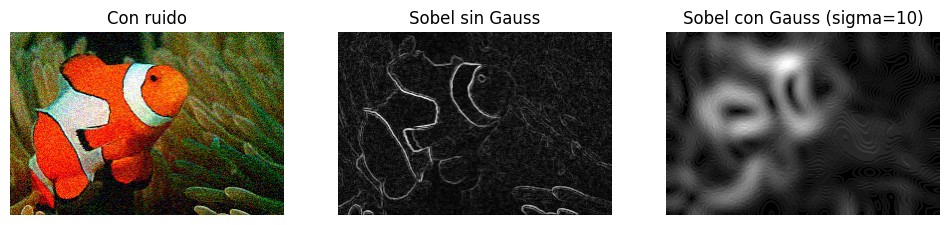

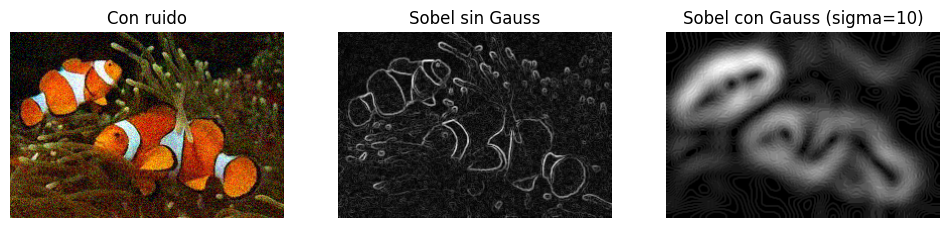

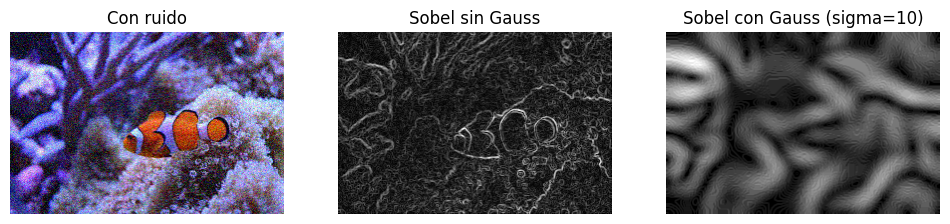

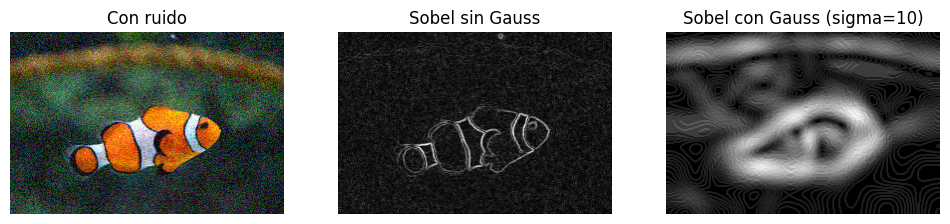

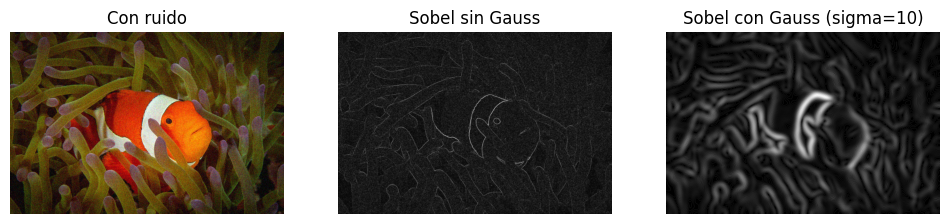

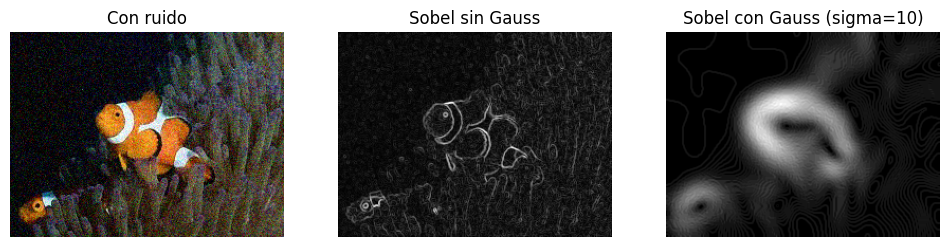

In [ ]:
# TODO Homework

np.random.seed(42)  # reproducible

imgs_noise = []
for img in imgs:
    ruido = np.random.normal(0, 25, img.shape)        # media 0, desviación 25 (escala 0-255)
    img_ruidosa = img.astype(np.float64) + ruido      # float para que la suma no haga overflow
    img_ruidosa = np.clip(img_ruidosa, 0, 255)        # corrige los valores fuera de [0, 255]
    imgs_noise.append(img_ruidosa.astype(np.uint8))  

def sobel_edge_detector_gaussian(img: np.array, filter: np.array, gauss_sigma: float, gauss_filter_shape: Optional[List] = None, verbose: bool = False) -> np.array:
    # TODO Transform the img to grayscale
    gray_img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) 
    
    # TODO Get a blurry img to improve edge detections
    _,blurred = gaussian_blur(img=gray_img, sigma=gauss_sigma, filter_shape=gauss_filter_shape, verbose=verbose)
    
    # Re-scale
    blurred = blurred/255
    
    # TODO Get vertical edges
    v_edges = cv2.filter2D(blurred, -1, filter)
    
    # TODO Transform the filter to get the orthogonal edges
    filter = filter.T
    
    # TODO Get horizontal edges
    h_edges = cv2.filter2D(blurred, -1, filter)
    
    # TODO Get edges
    sobel_edges_img = np.hypot(v_edges,h_edges)
    
    # Get edges angle
    theta = np.arctan2(h_edges,v_edges)
    
    # Visualize if needed
    if verbose:
        show_image(img=sobel_edges_img, img_name="Sobel Edges")
    
    return np.squeeze(sobel_edges_img), np.squeeze(theta)

def sobel_edge_detector_no_gaussian(img: np.array, filter: np.array, verbose: bool = False) -> np.array:
    # TODO Transform the img to grayscale
    gray_img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) 
    
    # Re-scale
    img_rescale = gray_img/255
    
    # TODO Get vertical edges
    v_edges = cv2.filter2D(img_rescale, -1, filter)
    
    # TODO Transform the filter to get the orthogonal edges
    filter = filter.T
    
    # TODO Get horizontal edges
    h_edges = cv2.filter2D(img_rescale, -1, filter)
    
    # TODO Get edges
    sobel_edges_img = np.hypot(v_edges,h_edges)
    
    # Get edges angle
    theta = np.arctan2(h_edges,v_edges)
    
    # Visualize if needed
    if verbose:
        show_image(img=sobel_edges_img, img_name="Sobel Edges")
    
    return np.squeeze(sobel_edges_img), np.squeeze(theta)

gauss_sigma = 10 #Initial value, possible changes.
gauss_filter_shape = None
sobel_filter = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
img_sobel_gauss = []
for img in imgs_noise:
    img_sobel_gauss.append(sobel_edge_detector_gaussian(img,sobel_filter,gauss_sigma,gauss_filter_shape,False)[0])

img_sobel_not_gauss = []
for img in imgs_noise:
    img_sobel_not_gauss.append(sobel_edge_detector_no_gaussian(img,sobel_filter,False)[0])

titulos = ["Con ruido", "Sobel sin Gauss", f"Sobel con Gauss (sigma={gauss_sigma})"]

for i in range(len(imgs_noise)):
    #Los 3 tipos de imágenes pero convertimos la de ruido a RGB que es lo que espera matplotlib
    imagenes = [cv2.cvtColor(imgs_noise[i], cv2.COLOR_BGR2RGB), img_sobel_not_gauss[i], img_sobel_gauss[i]]
    plt.figure(figsize=(12, 4))
    for j in range(3):
        plt.subplot(1, 3, j + 1)
        plt.imshow(imagenes[j], cmap='gray')  # cmap solo afecta a las de un canal
        plt.title(titulos[j])
        plt.axis('off')
    plt.show()   

### **Pregunta A.2:** Utilice la librería ``scikit-image`` y compare el efecto de los filtros Sobel, Canny y Prewitt sobre las imágenes de la carpeta ``data``. ¿Qué diferencias observa entre los filtros? ¿Puede obtener alguna conclusión y/o patrón?

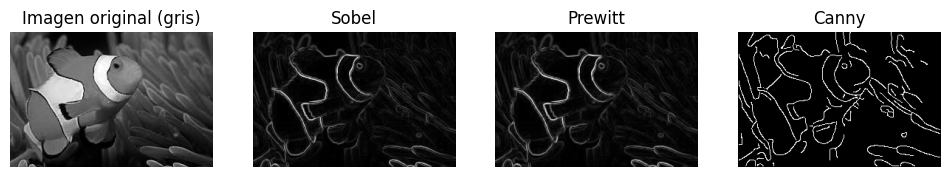

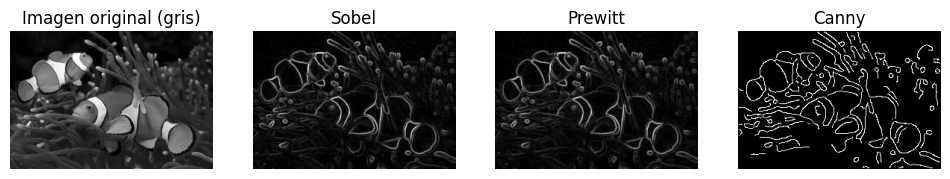

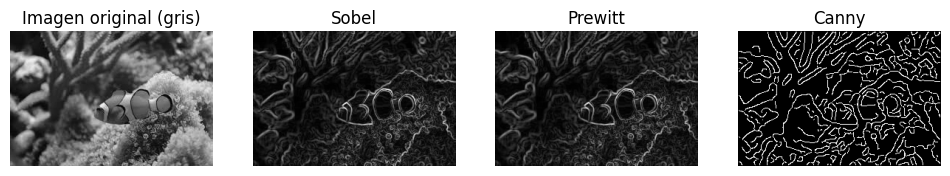

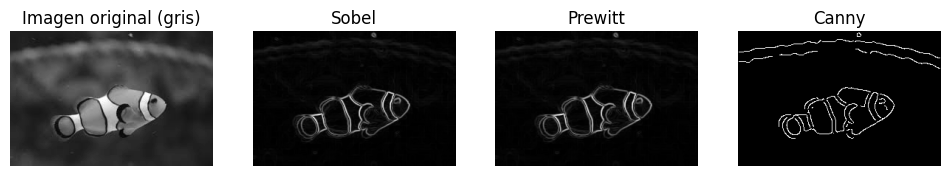

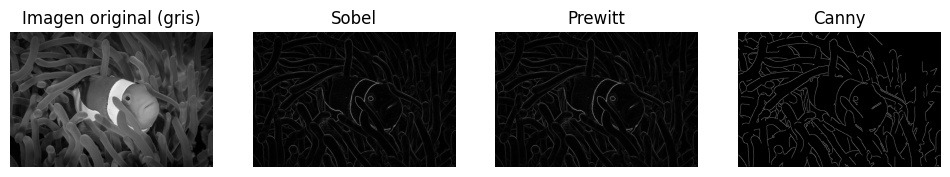

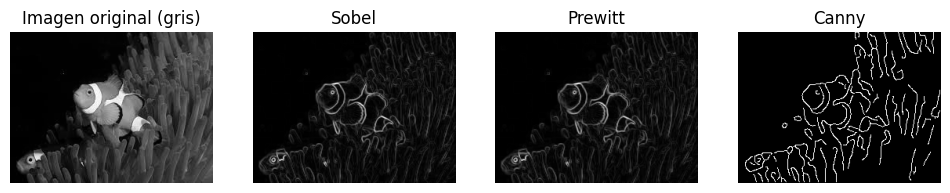

In [83]:
# TODO Homework
from skimage.filters import sobel, prewitt
from skimage.feature import canny

imgs_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in imgs]

imgs_sobel = []
for i1 in imgs_gray:
    imgs_sobel.append(sobel(i1))

imgs_prewitt = []
for i2 in imgs_gray:
    imgs_prewitt.append(prewitt(i2))

imgs_canny = []
for i3 in imgs_gray:
    imgs_canny.append(canny(i3,sigma=2))

titulos = ["Imagen original (gris)","Sobel", "Prewitt", "Canny"]

for i in range(len(imgs_gray)):
    imagenes = [imgs_gray[i],imgs_sobel[i], imgs_prewitt[i], imgs_canny[i]]
    plt.figure(figsize=(12, 4))
    for j in range(4):
        plt.subplot(1, 4, j + 1)
        plt.imshow(imagenes[j], cmap='gray')  # cmap solo afecta a las de un canal
        plt.title(titulos[j])
        plt.axis('off')
    plt.show()

### **Pregunta A.3:** Añada ruido impulsivo ("sal y pimienta") a una imagen de la carpeta ``data`` corrompiendo un 5 % de los píxeles. Aplique sobre la imagen ruidosa un filtro gaussiano (``cv2.GaussianBlur()``) y uno de mediana (``cv2.medianBlur()``) y explique por qué se obtienen resultados distintos.

In [ ]:
# TODO Homework

## **Apartado B:** Operadores Morfológicos

Para resolver este partado, deberá seguir los siguientes pasos:

1. **Tarea B.1.** Defina el método ``binarize()`` para binarizar imágenes.
2. **Tarea B.2.** Defina el método ``custom_dilate()``.
3. **Tarea B.3.** Defina el método ``custom_erode()``.
4. **Pregunta B.1** Aplique los métodos ``custom_dilate()`` y ``custom_erode()`` a todas las imágenes de la carpeta ``data``.


### **Tarea B.1.** Defina el método ``binarize()`` para binarizar imágenes.

In [ ]:
# TODO Homework: define the binarization method
def binarize(img: np.array, threshold: int = 127):
    binary_img = None
    return binary_img

### **Tarea B.2.** Defina el método ``custom_dilate()``

In [ ]:
# TODO Homework: define the dilation method
def custom_dilate(img):
    # TODO pad the original image so it can keep dimensions after processing
    padded = np.pad()
    
    # TODO get img shape
    width = None
    height = None
    
    # TODO Create an element with the same dimensions as the padded img
    dilated = np.zeros()
    
    for j in range(height):
        for i in range(width):
            # TODO Add logic to the operation
            pass
            
    # TODO Select the region of interest (ROI). Modify if needed
    dilated = dilated[1:height+1, 1:width+1]
    
    return dilated

### **Tarea B.3.** Defina el método ``custom_erode()``

In [ ]:
# TODO Homework: define the erotion method
def custom_erode(img):
    eroded = None
    
    return eroded

### **Pregunta B.1** Aplique los métodos ``custom_dilate()`` y ``custom_erode()`` a todas las imágenes de la carpeta ``data``.

In [ ]:
# TODO Homework